# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [1]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# complete
print(f"matplotlib version: {plt.matplotlib.__version__}")
print(f"seaborn version: {sns.__version__}")
# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.5.4
Pandas version: 3.0.6
matplotlib version: 3.11.2
seaborn version: 0.13.2


In [2]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [3]:
# Write your code here

S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = ([0.3, 0.7])
bias = 0.5

# 1. Compute linear combination z
z =  S @ theta + 0.5 
print("z =", z[0]) 

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5) 
probabilities = 1 / (1 + np.exp(-z)) 
print("probabilities :",probabilities.round(4))
# Identify predicted spam emails 
predicted_spam = probabilities >= 0.5
print("predicted_spam :",predicted_spam)

z = 6.3
probabilities : [0.9982 0.8581 0.991  0.9002]
predicted_spam : [ True  True  True  True]


In [4]:
# Auto-graded cell (S)
# Skip it

In [5]:
# Auto-graded cell (theta)
# Skip it

In [6]:
# Auto-graded cell (bias)
# Skip it

In [7]:
# Auto-graded cell (z)
# Skip it

In [8]:
# Auto-graded cell (probabilities) 
# Skip it

In [9]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [10]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [11]:
# Auto graded cell (log)
# skip it

In [12]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"
log.loc[rng.choice(n, 12, replace=False), "failed_attempts"] = rng.integers(5, 11, 12)
# Write your code here

In [13]:
# Autograded cell (Failed attempts)
# Skip it

In [14]:
# Insert 10 missing values randomly
log.loc[rng.choice(n, 10, replace=False), "duration_min"] = np.nan
# Write your code here

In [15]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [16]:
# Write your code here
ru_log_at_least_five_attempts = len(log[(log["country"] == "RU") & (log["failed_attempts"] >= 5)])
print(ru_log_at_least_five_attempts)
# ru_log_at_least_five_attempts = ...

2


In [17]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [18]:
# Write your code here
user_max_failed_attempts = log.groupby("user")["failed_attempts"].sum().sort_values(ascending=False).index[0]
print(user_max_failed_attempts)
# user_max_failed_attempts = 

yacine


In [19]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [20]:
# Write your code here
log['long_session'] = (log['duration_min'] > 30).astype(int)

In [21]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

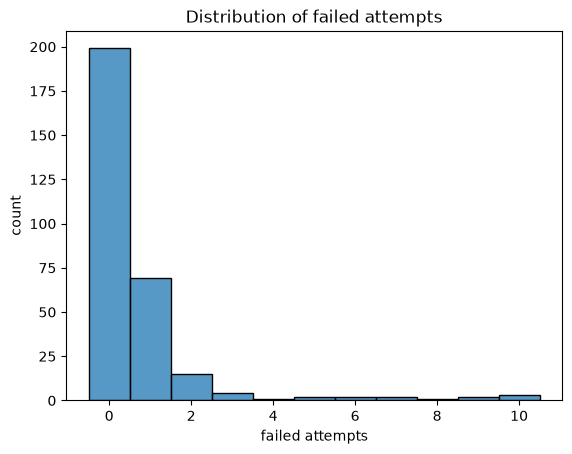

In [22]:
# Draw the histogram of failed_attempts.
# Write your code here
sns.histplot(log["failed_attempts"], bins=range(0, 12), discrete=True)
plt.title("Distribution of failed attempts")
plt.xlabel("failed attempts")
plt.ylabel("count")
plt.show()

In [23]:
# Auto-graded cell - Skip it...

In [24]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

IndentationError: unexpected indent (1357432129.py, line 2)

In [25]:
# Write your code here
answer_q2 = "B"

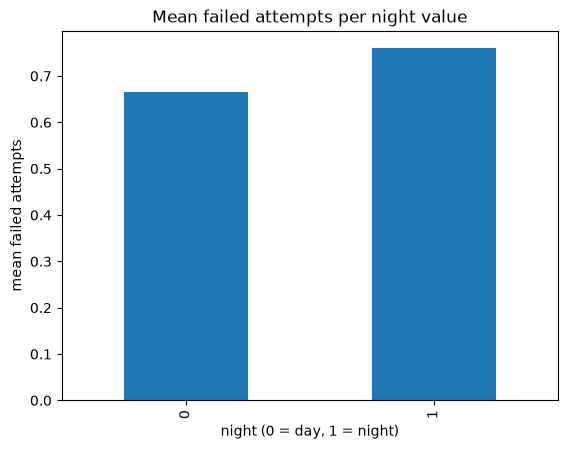

In [26]:
# 3. Draw a bar chart of the mean failed_attempts per night value.
log["night"] = (log["hour"] < 6).astype(int)      
log.groupby("night")["failed_attempts"].mean().plot.bar(title="Mean failed attempts per night value")
plt.xlabel("night (0 = day, 1 = night)")
plt.ylabel("mean failed attempts")
plt.show()
# Write your code here

In [27]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [28]:
# Write your code here
# Please write a sentence response instead of code
# X[:, 2] returns all 300 column of the third column (index 2) of X,as 1-D array of shape (300,).

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [30]:
# Write your code here
#df.isna().sum()

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [31]:
# Write your code here
# A box plot of failed attempts grouped by country .

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [32]:
# Write your code here
# We scale features so that those with large ranges (e.g. `duration_min`) don't dominate those with small ranges, and so gradient-based training converges faster.

Commit the logins_clean.csv.(0.5 point)

In [33]:
# save the cleaned table in login_clean.csv
log["duration_min"] = log["duration_min"].fillna(log["duration_min"].median())
log["night"] = (log["hour"] < 6).astype(int)
log.to_csv("logins_clean.csv", index=False)
# Write your code here

In [34]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [35]:
# Write your code here
df = pd.read_csv("logins_clean.csv")
cols = ["hour", "failed_attempts", "duration_min", "night"]

X = df[cols].to_numpy()
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

print(X_scaled.shape)

(300, 4)


In [36]:
import numpy as np
import pandas as pd
